# TP 01 — Coordonnées cylindriques et cartésiennes

## Cinématique du point matériel avec Python

Dans ce TP, nous allons utiliser Python pour représenter un point matériel dans l'espace.

L'objectif est de comprendre une idée fondamentale en mécanique :

$$
\text{un même point matériel peut être décrit avec plusieurs systèmes de coordonnées.}
$$

Nous allons partir des coordonnées cylindriques :

$$
(r, \theta, z)
$$

puis calculer les coordonnées cartésiennes correspondantes :

$$
(x, y, z)
$$

Enfin, nous visualiserons le même point dans l'espace.

<div style="background-color:#eef6ff; padding:12px; border-left:5px solid #1f77b4;">

<strong>Idée</strong>

Les coordonnées ne sont pas le point.  
Les coordonnées sont une manière de décrire la position du point.

Le point matériel $M$ est le même, mais sa description peut changer selon le système de coordonnées choisi.

</div>

## 1. Rappel de cours

En mécanique du point matériel, on modélise un objet par un point $M$.

Pour décrire sa position, on introduit le vecteur position :

$$
\vec{OM}
$$

où $O$ est l'origine du repère et $M$ la position du point matériel.

En coordonnées cartésiennes, le point est décrit par :

$$
M = (x, y, z)
$$

En coordonnées cylindriques, le même point est décrit par :

$$
M = (r, \theta, z)
$$

où :

- $r$ est la distance du point à l'axe vertical $z$ ;
- $\theta$ est l'angle dans le plan horizontal $(x, y)$ ;
- $z$ est la hauteur du point.

## 2. Passage des coordonnées cylindriques aux coordonnées cartésiennes

À partir des coordonnées cylindriques $(r, \theta, z)$, on obtient les coordonnées cartésiennes $(x, y, z)$ avec :

$$
x = r\cos(\theta)
$$

$$
y = r\sin(\theta)
$$

$$
z_{\mathrm{cart}} = z
$$

La coordonnée $z$ ne change pas : elle représente toujours la hauteur du point.

<div style="background-color:#fff4e5; padding:12px; border-left:5px solid #ff9800;">

<strong>Attention aux unités</strong>

En Python, les fonctions `np.sin` et `np.cos` utilisent des angles en radians.

Si l'angle est donné en degrés, il faut le convertir avec :

```python
theta = np.radians(theta_degrees)
```

</div>

## 3. Importer les bibliothèques

Nous allons utiliser :

- `NumPy` pour les calculs numériques ;
- `Matplotlib` pour la visualisation 3D.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

## 4. Définir un point en coordonnées cylindriques

On définit un point matériel $M$ par ses coordonnées cylindriques :

$$
r = 4~\mathrm{m}
$$

$$
\theta = 35^\circ
$$

$$
z = 3~\mathrm{m}
$$

Pour les calculs Python, on convertit l'angle en radians.

In [ ]:
# Cylindrical coordinates of the material point M
r = 4.0                    # radial distance [m]
theta_degrees = 35.0       # angle [deg]
z = 3.0                    # height [m]

# NumPy trigonometric functions use radians
theta = np.radians(theta_degrees)

print("Cylindrical coordinates")
print(f"r = {r:.3f} m")
print(f"theta = {theta_degrees:.3f} deg = {theta:.3f} rad")
print(f"z = {z:.3f} m")

Cylindrical coordinates
r = 4.000 m
theta = 45.000 deg = 0.785 rad
z = 3.000 m


## 5. Fonction de conversion

Écrivez la focntion `cylindrical_to_cartesian` qui prend en entrée les coordonnées cylindriques $(r, \theta, z)$ d’un point matériel et qui renvoie ses coordonnées cartésiennes $(x, y, z)$.

In [ ]:
def cylindrical_to_cartesian(r, theta, z):
    '''
    Convert cylindrical coordinates to Cartesian coordinates.

    Parameters
    ----------
    r : float
        Radial distance from the z-axis [m].
    theta : float
        Angular coordinate in the xy-plane [rad].
    z : float
        Height coordinate [m].

    Returns
    -------
    x : float
        Cartesian coordinate along x [m].
    y : float
        Cartesian coordinate along y [m].
    z_cart : float
        Cartesian coordinate along z [m].
    '''

    # Projection of the radial distance along the x-axis
    x = 5*r * np.cos(theta)

    # Projection of the radial distance along the y-axis
    y = r * np.sin(theta)

    # The vertical coordinate is unchanged
    z_cart = z

    return x, y, z_cart

<div style="background-color:#eef6ff; padding:12px; border-left:5px solid #1f77b4;">

<strong>Interprétation</strong>

Le point physique n'a pas changé.

Nous avons seulement changé sa description mathématique :

$$
(r, \theta, z) \longrightarrow (x, y, z)
$$

</div>

## 6. Visualisation 3D

On applique maintenant la fonction de conversion pour obtenir les coordonnées cartésiennes de $M$, puis on visualise le même point dans l'espace.

La figure montre deux manières de lire la position du point :

- un repère cartésien, représenté par un cube de lecture ;
- une description cylindrique, représentée par un cylindre de rayon $r$ et de hauteur $z$.

Le point $M$ est unique : les deux descriptions correspondent au même point dans l'espace.

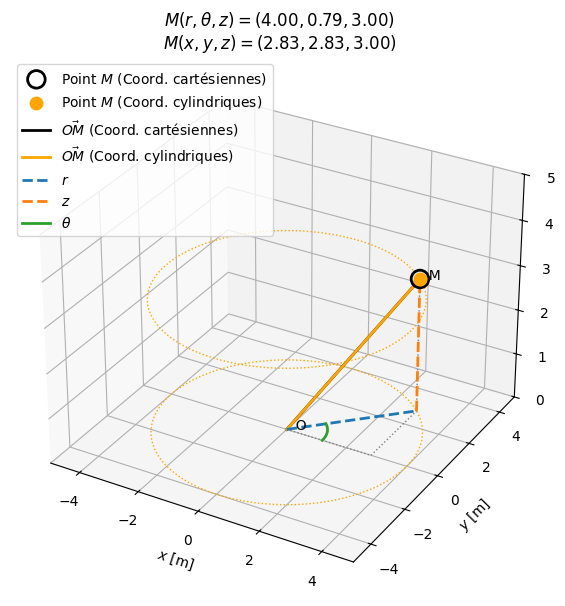

In [16]:
def plot_point_cylindrical(r, theta, z):
    """
    Plot a point M described by cylindrical coordinates.
    """
    x, y, z_cart = cylindrical_to_cartesian(r, theta, z)

    fig, ax = plt.subplots(
        figsize=(7, 7),
        subplot_kw={"projection": "3d"}
    )

    # ------------------------------------------------------------------
    # Subtle cylindrical guide
    # ------------------------------------------------------------------
    angle = np.linspace(0.0, 2.0 * np.pi, 100)

    x_bot, y_bot, z_bot = cylindrical_to_cartesian(r, angle,np.zeros_like(angle))
    x_top, y_top, z_top = cylindrical_to_cartesian(r, angle,z * np.ones_like(angle))

    # Bottom and top circles of the cylinder
    ax.plot(x_bot, y_bot, z_bot, linestyle=":", color='orange', linewidth=1)
    ax.plot(x_top, y_top, z_top, linestyle=":", color='orange', linewidth=1)

    # ------------------------------------------------------------------
    # Subtle Cartesian box
    # ------------------------------------------------------------------
    x_r = r * np.cos(theta)
    y_r = r * np.sin(theta)
    z_r = z
    ax.plot([0, x_r], [0, 0], [0, 0], linestyle=":", color='grey', linewidth=1)
    ax.plot([x_r, x_r], [0, y_r], [0, 0], linestyle=":", color='grey', linewidth=1)
    ax.plot([x_r, x_r], [y_r, y_r], [0, z_r], linestyle=":", color='grey', linewidth=1)


    # ------------------------------------------------------------------
    # Point and physical vectors
    # ------------------------------------------------------------------
    ax.scatter(x_r, y_r,  z_r, color='black',facecolors="none", s=160, linewidths=2, label=r"Point $M$ (Coord. cartésiennes)")
    ax.scatter(x, y, z_cart, color='orange',  s=80, label=r"Point $M$ (Coord. cylindriques)")

    # Position vector OM
    ax.plot([0, x_r], [0, y_r], [0, z_r], linewidth=2, color='black',  label=r"$\vec{OM}$ (Coord. cartésiennes)")
    ax.plot([0, x], [0, y], [0, z_cart],  linewidth=2, color='orange', label=r"$\vec{OM}$ (Coord. cylindriques)")

    # Cylindrical components
    ax.plot([0, x], [0, y], [0, 0], linestyle="--", linewidth=2, label=r"$r$")
    ax.plot([x, x], [y, y], [0, z_cart], linestyle="--", linewidth=2, label=r"$z$")

    # Angle theta in the xy-plane
    arc_radius = 0.3 * r
    angle_values = np.linspace(0.0, theta, 50)

    ax.plot(
        arc_radius * np.cos(angle_values),
        arc_radius * np.sin(angle_values),
        np.zeros_like(angle_values),
        linewidth=2,
        label=r"$\theta$"
    )

    # Text labels
    ax.text(0, 0, 0, "  O")
    ax.text(x, y, z_cart, "  M")

    # Axis limits
    limit = max(r, z_cart, abs(x), abs(y), 1.0) + 1.0
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_zlim(0, limit)

    ax.set_xlabel(r"$x$ [m]")
    ax.set_ylabel(r"$y$ [m]")
    ax.set_zlabel(r"$z$ [m]")

    ax.set_title(
        rf"$M(r,\theta,z)=({r:.2f}, {theta:.2f}, {z:.2f})$"
        "\n"
        rf"$M(x,y,z)=({x:.2f}, {y:.2f}, {z_cart:.2f})$"
    )

    ax.legend()
    plt.show()

plot_point_cylindrical(r, theta, z)

## 7. Questions

1. Quelle coordonnée cylindrique correspond à la hauteur du point ?
2. Que représente géométriquement la coordonnée $r$ ?
3. Pourquoi faut-il convertir l'angle en radians avant d'utiliser `np.cos` et `np.sin` ?
4. Le point physique change-t-il lorsqu'on passe de $(r, \theta, z)$ à $(x, y, z)$ ?
5. Dans quel type de problème les coordonnées cylindriques sont-elles plus naturelles que les coordonnées cartésiennes ?

## Conclusion

Dans ce TP, nous avons vu qu'un même point matériel peut être décrit de plusieurs manières.

En coordonnées cylindriques :

$$
M = (r, \theta, z)
$$

En coordonnées cartésiennes :

$$
M = (x, y, z)
$$

Le point $M$ est le même.  
Seule sa description change.

Dans la suite, nous ferons évoluer ce point au cours du temps :

$$
x = x(t), \quad y = y(t), \quad z = z(t)
$$

ce qui nous permettra d'introduire la trajectoire, la vitesse et l'accélération.